# Object detection transfer learning

In [1]:
import random
import numpy as np
import torch
SEED = 42

def set_seed(seed=SEED):
    """Re-seed all RNGs. Call this again right before any stage
    (dataset split, training loop, etc.) that must be reproducible,
    since intervening code (e.g. anchor k-means) may have already
    consumed randomness from these generators."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)


### Yolov2 architecture

In [2]:
import torch
import torch.nn as nn

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, batch_norm=True, activation=True):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size, stride, padding,
            bias=not batch_norm,
        )
        self.bn = nn.BatchNorm2d(out_channels) if batch_norm else nn.Identity()
        self.activation = nn.LeakyReLU(0.1, inplace=True) if activation else nn.Identity()

    def forward(self, x):
        return self.activation(self.bn(self.conv(x)))


class ReorgLayer(nn.Module): 
    def __init__(self, stride=2):
        super().__init__()
        self.stride = stride
 
    def forward(self, x):
        B, C, H, W = x.shape
        s = self.stride
        x = x.view(B, C, H // s, s, W // s, s)
        x = x.permute(0, 3, 5, 1, 2, 4).contiguous()
        x = x.view(B, C * s * s, H // s, W // s)
        return x

class DarknetStageA(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            ConvBlock(3, 32, 3), nn.MaxPool2d(2, 2),
            ConvBlock(32, 64, 3), nn.MaxPool2d(2, 2),

            ConvBlock(64, 128, 3),
            ConvBlock(128, 64, 1),
            ConvBlock(64, 128, 3), nn.MaxPool2d(2, 2),

            ConvBlock(128, 256, 3),
            ConvBlock(256, 128, 1),
            ConvBlock(128, 256, 3), nn.MaxPool2d(2, 2),

            ConvBlock(256, 512, 3),
            ConvBlock(512, 256, 1),
            ConvBlock(256, 512, 3),
            ConvBlock(512, 256, 1),
            ConvBlock(256, 512, 3),
        )

    def forward(self, x):
        return self.net(x)

class DarknetStageB(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.MaxPool2d(2, 2),
            ConvBlock(512, 1024, 3),
            ConvBlock(1024, 512, 1),
            ConvBlock(512, 1024, 3),
            ConvBlock(1024, 512, 1),
            ConvBlock(512, 1024, 3),
        )

    def forward(self, x):
        return self.net(x)

class DetectionHead(nn.Module):
    def __init__(self, num_classes=80, num_anchors=5):
        super().__init__()
        self.pre_route = nn.Sequential(
            ConvBlock(1024, 1024, 3),
            ConvBlock(1024, 1024, 3),
        )
        self.passthrough_reduce = ConvBlock(512, 64, 1)
        self.reorg = ReorgLayer(stride=2)

        self.post_route = ConvBlock(1280, 1024, 3)

        out_channels = num_anchors * (5 + num_classes)
        self.final_conv = ConvBlock(
            1024, out_channels, 1, batch_norm=False, activation=False
        )

    def forward(self, backbone_out, passthrough_src):
        x = self.pre_route(backbone_out)

        p = self.passthrough_reduce(passthrough_src)
        p = self.reorg(p)

        x = torch.cat([p, x], dim=1)
        x = self.post_route(x)
        x = self.final_conv(x)
        return x


class YOLOv2(nn.Module):
    def __init__(self, num_classes=80, num_anchors=5):
        super().__init__()
        self.num_classes = num_classes
        self.num_anchors = num_anchors

        self.stage_a = DarknetStageA()
        self.stage_b = DarknetStageB()
        self.head = DetectionHead(num_classes, num_anchors)

    def forward(self, x):
        passthrough_src = self.stage_a(x)
        backbone_out = self.stage_b(passthrough_src)
        out = self.head(backbone_out, passthrough_src)
        return out

### Function for loading darknet weights into pytorch

In [3]:
import numpy as np
def load_darknet_weights(model, weight_file):
    with open(weight_file, "rb") as f:
        #YOLOv2 headers are 4 int32s (major, minor, revision, seen)
        _ = np.fromfile(f, dtype=np.int32,count=4)
        weights = np.fromfile(f, dtype=np.float32)
        
    ptr = 0
    
    for m in model.modules():
        if m.__class__.__name__ == "ConvBlock":
                       
            # If batch_norm is active
            if getattr(m, 'bn', None) is not None and not isinstance(m.bn, nn.Identity):
                num_bn = m.bn.bias.numel()
                num_conv = m.conv.weight.numel()
                
                # Check if we have enough weights left for this entire block
                if ptr + (num_bn * 4) + num_conv > len(weights):
                    print(f"Backbone weights loaded. Stopping at custom layers ({ptr}/{len(weights)} loaded).")
                    break
                
                # Darknet saves Batch Norm in this specific order
                m.bn.bias.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.bias))
                ptr += num_bn
                
                m.bn.weight.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.weight))
                ptr += num_bn
                
                m.bn.running_mean.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.running_mean))
                ptr += num_bn
                
                m.bn.running_var.data.copy_(torch.from_numpy(weights[ptr : ptr + num_bn]).view_as(m.bn.running_var))
                ptr += num_bn
                
                # Load Conv weights
                m.conv.weight.data.copy_(torch.from_numpy(weights[ptr : ptr + num_conv]).view_as(m.conv.weight))
                ptr += num_conv
                
            else:
                # No Batch Norm
                num_conv_bias = m.conv.bias.numel()
                num_conv = m.conv.weight.numel()
                
                if ptr + num_conv_bias + num_conv > len(weights):
                    print(f"Backbone weights loaded. Stopping at custom layers ({ptr}/{len(weights)} loaded).")
                    break
                    
                m.conv.bias.data.copy_(torch.from_numpy(weights[ptr : ptr + num_conv_bias]).view_as(m.conv.bias))
                ptr += num_conv_bias
                
                m.conv.weight.data.copy_(torch.from_numpy(weights[ptr : ptr + num_conv]).view_as(m.conv.weight))
                ptr += num_conv
                
    return model

### Download dataset

In [4]:
import os
import glob
import torch
import torch.nn as nn
import torch.optim as optim
import xml.etree.ElementTree as ET
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Download BCCD Dataset directly from GitHub
!git clone https://github.com/Shenggan/BCCD_Dataset.git

BCCD_PATH = "./BCCD_Dataset/BCCD"
IMAGE_DIR = os.path.join(BCCD_PATH, "JPEGImages")
ANNOTATION_DIR = os.path.join(BCCD_PATH, "Annotations")

CLASSES = ['RBC', 'WBC', 'Platelets']
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 608 # YOLOv2 standard input size
GRID_SIZE = IMG_SIZE // 32 # 19x19 grid

fatal: destination path 'BCCD_Dataset' already exists and is not an empty directory.


### K means for finding anchor box size and finding best number of anchor boxes

In [5]:
import os
import glob
import xml.etree.ElementTree as ET
import numpy as np


def load_box_dims(annotation_dir):
    """
    Reads every BCCD XML annotation and returns an array of
    [width, height] for every ground-truth box, normalized 0-1
    (fraction of that image's width/height).
    """
    dims = []
    for xml_path in glob.glob(os.path.join(annotation_dir, "*.xml")):
        root = ET.parse(xml_path).getroot()
        img_w = float(root.find("size/width").text)
        img_h = float(root.find("size/height").text)

        for obj in root.findall("object"):
            b = obj.find("bndbox")
            w = (float(b.find("xmax").text) - float(b.find("xmin").text)) / img_w
            h = (float(b.find("ymax").text) - float(b.find("ymin").text)) / img_h
            dims.append([w, h]) #width/height pair of all bounding boxes is in common array and no grouping preserved

    return np.array(dims)


def iou_dist(box, clusters): #dont get confused with the iou used in nms, 
    """
    Shape-only IoU distance between one box [w, h] and a set of
    cluster centers [[w, h], ...] — same logic as anchor assignment, 
    just vectorized over all clusters at once. Returns 1 - IoU per cluster
    (so 0 = perfect match, used as a distance for k-means).
    """
    #in above docstring cluster center means box found using running k means on other boxes, it doesnt mean center coordinate of box
    inter = np.minimum(box[0], clusters[:, 0]) * np.minimum(box[1], clusters[:, 1])
    union = box[0] * box[1] + clusters[:, 0] * clusters[:, 1] - inter
    return 1 - inter / (union + 1e-6)


def kmeans_anchors(dims, k, n_iter=100, seed=0):
    """
    K-means clustering over box [w, h] dims using IoU-distance instead
    of Euclidean distance (standard approach from the YOLOv2 paper).
    Returns k cluster centers, sorted smallest-area to largest.
    """
    rng = np.random.default_rng(seed)
    clusters = dims[rng.choice(len(dims), k, replace=False)]  # random init

    for _ in range(n_iter):
        # assign every box to its nearest cluster (by IoU distance)
        distances = np.array([iou_dist(d, clusters) for d in dims])
        nearest = distances.argmin(axis=1)

        # recompute each cluster as the mean of the boxes assigned to it
        new_clusters = np.array([
            dims[nearest == i].mean(axis=0) if np.any(nearest == i) else clusters[i]
            for i in range(k)
        ])
        #new cluster box dimensions are mean of box dims which had dims nearest to it. if there was none then we dont change 

        if np.allclose(new_clusters, clusters):
            break
        clusters = new_clusters

    # sort by area (w*h) so anchors go small -> large, easier to read
    return clusters[np.argsort(clusters[:, 0] * clusters[:, 1])]


# --- Run it ---
dims = load_box_dims(ANNOTATION_DIR)  # uses ANNOTATION_DIR already defined earlier in your notebook
print(f"Loaded {len(dims)} boxes total")

for k in [2, 3, 4, 5, 6]:
    clusters = kmeans_anchors(dims, k)
    mean_iou = np.mean([1 - iou_dist(d, clusters).min() for d in dims])
    print(f"K={k}: mean IoU = {mean_iou:.4f}")

Loaded 4888 boxes total
K=2: mean IoU = 0.7602
K=3: mean IoU = 0.8017
K=4: mean IoU = 0.8328
K=5: mean IoU = 0.8460
K=6: mean IoU = 0.8579


In [6]:
import torch

def get_anchors_for_dataset(annotation_dir, k_range=range(2, 7), improvement_threshold=0.02, verbose=True):
    """
    Runs k-means over ground-truth box dims for each K in k_range,
    picks the smallest K where adding another anchor stops giving a
    meaningful IoU improvement (the "elbow"), and returns anchors
    ready to plug into the notebook.

    Parameters
    ----------
    annotation_dir : str
        Path to the XML annotations folder (e.g. ANNOTATION_DIR).
    k_range : iterable of int
        Which K values to try. Default 2-6.
    improvement_threshold : float
        Minimum relative IoU gain (e.g. 0.02 = 2%) required to justify
        moving to a larger K instead of stopping at the current one.
    verbose : bool
        Print the IoU-per-K table and the chosen K.

    Returns
    -------
    anchors : torch.Tensor, shape [K, 2]
        Chosen anchors, already normalized (0-1 image-fraction units) —
        no division by GRID_SIZE needed.
    best_k : int
        The K that was picked.
    """
    dims = load_box_dims(annotation_dir)
    if verbose:
        print(f"Loaded {len(dims)} boxes total")

    results = {}  # k -> (clusters, mean_iou)
    for k in k_range:
        clusters = kmeans_anchors(dims, k)
        mean_iou = np.mean([1 - iou_dist(d, clusters).min() for d in dims])
        results[k] = (clusters, mean_iou)
        if verbose:
            print(f"K={k}: mean IoU = {mean_iou:.4f}")

    # pick elbow: smallest K where the next K's improvement is below threshold
    ks = sorted(results.keys())
    best_k = ks[0]
    for i in range(len(ks) - 1):
        k_curr, k_next = ks[i], ks[i + 1]
        iou_curr, iou_next = results[k_curr][1], results[k_next][1]
        relative_gain = (iou_next - iou_curr) / (iou_curr + 1e-6)

        best_k = k_curr
        if relative_gain >= improvement_threshold:
            best_k = k_next  # worth moving up, keep going
        else:
            break  # diminishing returns, stop here

    chosen_clusters = results[best_k][0]

    if verbose:
        print(f"\nChosen K = {best_k} (elbow point)")
        print(f"Anchors:\n{chosen_clusters}")

    anchors = torch.tensor(chosen_clusters, dtype=torch.float32)
    return anchors, best_k

In [7]:
anchors, NUM_ANCHORS = get_anchors_for_dataset(ANNOTATION_DIR)

Loaded 4888 boxes total
K=2: mean IoU = 0.7602
K=3: mean IoU = 0.8017
K=4: mean IoU = 0.8328
K=5: mean IoU = 0.8460
K=6: mean IoU = 0.8579

Chosen K = 4 (elbow point)
Anchors:
[[0.06237392 0.0806256 ]
 [0.15291834 0.18717565]
 [0.17457502 0.23110267]
 [0.32905376 0.39712267]]


### Create pytorch dataset, dataloader and transforms

In [8]:
class BCCDDataset(Dataset):
    def __init__(self, image_dir, annotation_dir, anchors, transform=None):
        self.image_dir = image_dir
        self.annotation_paths = sorted(glob.glob(os.path.join(annotation_dir, "*.xml")))
        self.anchors = anchors 
        self.transform = transform
        
    def __len__(self):
        return len(self.annotation_paths)
    
    def __getitem__(self, idx):
        xml_path = self.annotation_paths[idx]
        tree = ET.parse(xml_path)
        root = tree.getroot()
        
        # Load image
        img_filename = root.find("filename").text
        img_path = os.path.join(self.image_dir, img_filename)
        image = Image.open(img_path).convert("RGB")
        orig_w, orig_h = image.size
        
        if self.transform:
            image = self.transform(image)
            
        # Target tensor shape: [num_anchors, grid_size, grid_size, 5 + num_classes]
        # 5 comes from: [objectness, cx, cy, w, h]
        target = torch.zeros((len(self.anchors), GRID_SIZE, GRID_SIZE, 5 + NUM_CLASSES))
        
        for obj in root.findall("object"):
            class_name = obj.find("name").text
            if class_name not in CLASSES:
                continue
            class_id = CLASSES.index(class_name)
            
            bndbox = obj.find("bndbox")
            xmin = float(bndbox.find("xmin").text) / orig_w
            ymin = float(bndbox.find("ymin").text) / orig_h
            xmax = float(bndbox.find("xmax").text) / orig_w
            ymax = float(bndbox.find("ymax").text) / orig_h
            
            # Convert to center x, center y, width, height (normalized 0 to 1)
            cx, cy = (xmin + xmax) / 2.0, (ymin + ymax) / 2.0
            w, h = xmax - xmin, ymax - ymin
            
            # Find grid cell coordinates
            cell_x, cell_y = int(cx * GRID_SIZE), int(cy * GRID_SIZE)
            
            # Find best anchor (simplified: match by shape/aspect ratio)
            # In a full implementation, you compute IoU between the true box and anchor boxes
            anchor_ious = []
            for a_w, a_h in self.anchors:
                # Compare width/height ratios
                inter = min(w, a_w) * min(h, a_h)
                union = (w * h) + (a_w * a_h) - inter
                anchor_ious.append(inter / (union + 1e-6))
            
            best_anchor = np.argmax(anchor_ious)
            
            # Populate target tensor (Only if no object is already assigned to this exact anchor/cell)
            if target[best_anchor, cell_y, cell_x, 0] == 0:
                target[best_anchor, cell_y, cell_x, 0] = 1.0 # Objectness score
                
                # Bbox coordinates relative to the cell
                target[best_anchor, cell_y, cell_x, 1:5] = torch.tensor([
                    cx * GRID_SIZE - cell_x, # cx relative to cell (0 to 1)
                    cy * GRID_SIZE - cell_y, # cy relative to cell (0 to 1)
                    torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
                    torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform
                ])
                
                # One-hot encode class
                target[best_anchor, cell_y, cell_x, 5 + class_id] = 1.0
                
        return image, target

In [9]:
# Transforms
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

In [10]:
# Re-seed here so this cell's outcome doesn't depend on what randomness
# earlier cells (e.g. anchor k-means) already consumed.
set_seed(SEED)

dataset = BCCDDataset(IMAGE_DIR, ANNOTATION_DIR, anchors, transform=transform)

# Split 80/20 train/val
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

# Separate generators per use so consuming one (e.g. the split) never
# shifts the state of another (e.g. the loader's shuffle order) --
# each is deterministic on its own regardless of execution order.
split_generator = torch.Generator()
split_generator.manual_seed(SEED)

train_dataset, val_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, val_size],
    generator=split_generator
)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

val_generator = torch.Generator()
val_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    generator=train_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    generator=val_generator
)


### Creating the model

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [12]:
model = YOLOv2(num_classes=NUM_CLASSES, num_anchors=NUM_ANCHORS).to(device)
model = load_darknet_weights(model, "darknet19_448.conv.23")

Backbone weights loaded. Stopping at custom layers (19831776/19831776 loaded).


### This cell defines the yolo loss

In [13]:
class YOLOv2Loss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss(reduction="sum")
        self.bce = nn.BCEWithLogitsLoss(reduction="sum")
        self.cross_entropy = nn.CrossEntropyLoss(reduction="sum")
        
        self.lambda_coord = 5.0
        self.lambda_noobj = 0.5
        
    def forward(self, predictions, target):
        # predictions shape: [B, 5 * (5 + 3), 19, 19]
        B = predictions.shape[0]
        # Reshape to [B, anchors, grid_y, grid_x, 5 + classes]
        predictions = predictions.view(B, NUM_ANCHORS, 5 + NUM_CLASSES, GRID_SIZE, GRID_SIZE).permute(0, 1, 3, 4, 2)
        
        # Masks for object / no object
        obj_mask = target[..., 0] == 1 # [B, 5, 19, 19]
        noobj_mask = target[..., 0] == 0
        
        # 1. No Object Loss (Penalize objectness score if nothing is there)
        noobj_loss = self.bce(predictions[..., 0][noobj_mask], target[..., 0][noobj_mask])
        
        # 2. Object Loss (Encourage objectness score if something is there)
        obj_loss = self.bce(predictions[..., 0][obj_mask], target[..., 0][obj_mask])
        
        # 3. Coordinate Loss (Center x,y and width,height)
        coord_loss = self.mse(torch.sigmoid(predictions[..., 1:3][obj_mask]), target[..., 1:3][obj_mask])
        coord_loss += self.mse(predictions[..., 3:5][obj_mask], target[..., 3:5][obj_mask])
        
        # 4. Class Loss
        class_loss = self.cross_entropy(predictions[..., 5:][obj_mask], torch.argmax(target[..., 5:][obj_mask], dim=1))
        
        # Combine weighted losses
        total_loss = (self.lambda_coord * coord_loss) + obj_loss + (self.lambda_noobj * noobj_loss) + class_loss
        return total_loss / B # average over batch

### This cell calculates loss on given set of images

In [14]:
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    
    with torch.no_grad():
        for images, targets in dataloader:
            images, targets = images.to(device), targets.to(device)
            
            # Forward pass
            predictions = model(images)
            loss = criterion(predictions, targets)
            total_loss += loss.item()
            
    avg_loss = total_loss / len(dataloader)
    print(f"Validation Loss: {avg_loss:.4f}")
    return avg_loss

### Checking the model before transfer learning

In [15]:
criterion = YOLOv2Loss()

# Evaluate BEFORE training
print("\n--- Baseline Zero-Shot Evaluation ---")
# This loss will be very high because the DetectionHead is completely random!
evaluate_model(model, val_loader, criterion, device)


--- Baseline Zero-Shot Evaluation ---


/tmp/ipykernel_8850/3503680706.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_8850/3503680706.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


Validation Loss: 504.6542


504.6541748046875

### NMS

In [16]:
def iou(pred1, pred2):
    c1x = pred1[1].item()
    c1y = pred1[2].item()
    w1 = pred1[3].item()
    h1 = pred1[4].item()

    c2x = pred2[1].item()
    c2y = pred2[2].item()
    w2 = pred2[3].item()
    h2 = pred2[4].item()


    h_intx = h1/2 + h2/2 - abs(c1y-c2y)
    w_intx = w1/2 + w2/2 - abs(c1x-c2x)
    intx=0
    if h_intx>0 and w_intx>0:
        intx = h_intx*w_intx
    union = w1*h1 + w2*h2 - intx
    union = max(union, 1e-6)

    return intx/union

### This function is there to help us visualise and compare predictions and ground truth

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np


def decode_predictions(predictions, anchors, conf_thresh=0.5, iou_thresh=0.5):
    """
    Decodes the YOLO grid back to bounding boxes.
    This will return all boxes above the confidence threshold.
    """

    B = predictions.shape[0]

    predictions = predictions.view(B, NUM_ANCHORS, 5 + NUM_CLASSES, GRID_SIZE, GRID_SIZE).permute(0, 1, 3, 4, 2)
    
    # Apply sigmoid to objectness, cx, cy
    predictions[..., 0:3] = torch.sigmoid(predictions[..., 0:3])
    # Apply softmax to classes
    predictions[..., 5:] = torch.softmax(predictions[..., 5:], dim=-1)
    
    boxes = []

    suppressed_objects = set()

    for b in range(B):
            for a in range(NUM_ANCHORS):
                for y in range(GRID_SIZE):
                    for x in range(GRID_SIZE):
                        cx = (predictions[b, a, y, x, 1].item() + x) / GRID_SIZE
                        cy = (predictions[b, a, y, x, 2].item() + y) / GRID_SIZE
                        w = (torch.exp(predictions[b, a, y, x, 3]) * anchors[a][0]).item()
                        h = (torch.exp(predictions[b, a, y, x, 4]) * anchors[a][1]).item()
                        predictions[b,a,y,x,1]=cx
                        predictions[b,a,y,x,2]=cy
                        predictions[b,a,y,x,3]=w
                        predictions[b,a,y,x,4]=h


    NUM_FEATURES = predictions.shape[-1]
    flat_preds = predictions.contiguous().view(B, -1, NUM_FEATURES)
    sort_indices = torch.argsort(flat_preds[..., 0], dim=1, descending=True)
    batch_indexer = torch.arange(B).unsqueeze(1)
    sorted_predictions = flat_preds[batch_indexer, sort_indices]
    N = sorted_predictions.shape[1]


    for b in range(B):
        b_dicts = []
        
        for i in range(N):
            if (b, i) in suppressed_objects:
                continue

            conf = sorted_predictions[b, i, 0].item()
            
            if conf > conf_thresh:
                cx = sorted_predictions[b, i, 1].item()
                cy = sorted_predictions[b, i, 2].item() 
                w = sorted_predictions[b, i, 3].item() 
                h = sorted_predictions[b, i, 4].item() 

                class_probs = sorted_predictions[b, i, 5:].detach().cpu().numpy()
                class_id = int(np.argmax(class_probs))
                class_score = conf * class_probs[class_id]
                
                xmin = (cx - w/2) * IMG_SIZE
                ymin = (cy - h/2) * IMG_SIZE

                
                for i2 in range(N):
                    if i2==i:
                        continue
                    class_probs2 = sorted_predictions[b, i2, 5:].detach().cpu().numpy()
                    class_id2 = int(np.argmax(class_probs2))
                    Iou = iou(sorted_predictions[b, i], sorted_predictions[b, i2])
                    if Iou>iou_thresh and class_id2==class_id:
                        suppressed_objects.add((b, i2))
                                
                                
                b_dicts.append({
                    'bbox': [xmin, ymin, w * IMG_SIZE, h * IMG_SIZE],
                    'class_id': class_id,
                    'score': class_score
                })
                        
        boxes.append(b_dicts)
        
    return boxes


def plot_comparisons(model, dataloader, device, anchors, num_images=4, conf_thresh=0.5,iou_thresh=0.1):
    model.eval()
    images_shown = 0
    colors = ['r', 'g', 'b'] # RBC, WBC, Platelets
    
    fig, axes = plt.subplots(num_images, 2, figsize=(12, 6 * num_images))
    if num_images == 1: axes = [axes]
    
    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            predictions = model(images)
            
            # Call decode_predictions 
            pred_boxes = decode_predictions(predictions, anchors.to(device), conf_thresh=conf_thresh, iou_thresh=iou_thresh)
            
            for i in range(images.shape[0]):
                if images_shown >= num_images:
                    plt.tight_layout()
                    plt.show()
                    return
                
                img = images[i].cpu().permute(1, 2, 0).numpy()
                ax_gt = axes[images_shown][0]
                ax_pred = axes[images_shown][1]
                
                # --- PLOT GROUND TRUTH ---
                ax_gt.imshow(img)
                ax_gt.set_title(f"Ground Truth (Image {images_shown+1})", fontsize=14)
                ax_gt.axis('off')
                
                target = targets[i]
                obj_mask = target[..., 0] == 1
                indices = obj_mask.nonzero(as_tuple=True)
                
                for a, y, x in zip(*indices):
                    cx_rel, cy_rel, tw, th = target[a, y, x, 1:5]
                    cx = (cx_rel.item() + x.item()) / GRID_SIZE
                    cy = (cy_rel.item() + y.item()) / GRID_SIZE
                    w = (torch.exp(tw) * anchors[a][0]).item()
                    h = (torch.exp(th) * anchors[a][1]).item()
                    class_id = torch.argmax(target[a, y, x, 5:]).item()
                    
                    xmin = (cx - w / 2) * IMG_SIZE
                    ymin = (cy - h / 2) * IMG_SIZE
                    color = colors[class_id]
                    
                    rect = patches.Rectangle((xmin, ymin), w * IMG_SIZE, h * IMG_SIZE, linewidth=2, edgecolor=color, facecolor='none')
                    ax_gt.add_patch(rect)
                    ax_gt.text(xmin, ymin - 5, CLASSES[class_id], color=color, fontsize=10, weight='bold', bbox=dict(facecolor='white', alpha=0.6, pad=0, edgecolor='none'))

                # --- PLOT PREDICTIONS ---
                ax_pred.imshow(img)
                ax_pred.set_title(f"Predictions (Image {images_shown+1})", fontsize=14)
                ax_pred.axis('off')
                
                for box in pred_boxes[i]:
                    xmin, ymin, width, height = box['bbox']
                    class_id = box['class_id']
                    color = colors[class_id]
                    
                    rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor=color, facecolor='none')
                    ax_pred.add_patch(rect)
                    ax_pred.text(xmin, ymin - 5, f"{CLASSES[class_id]}: {box['score']:.2f}", color=color, fontsize=8, weight='bold', bbox=dict(facecolor='white', alpha=0.4, pad=0, edgecolor='none'))
                    
                images_shown += 1

### Predictions of model before any transfer learning is done


--- Visualizing Predictions BEFORE Training ---
Notice how the boxes are random noise because the DetectionHead is randomlisinstancey initialized.


/tmp/ipykernel_8850/3503680706.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_8850/3503680706.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


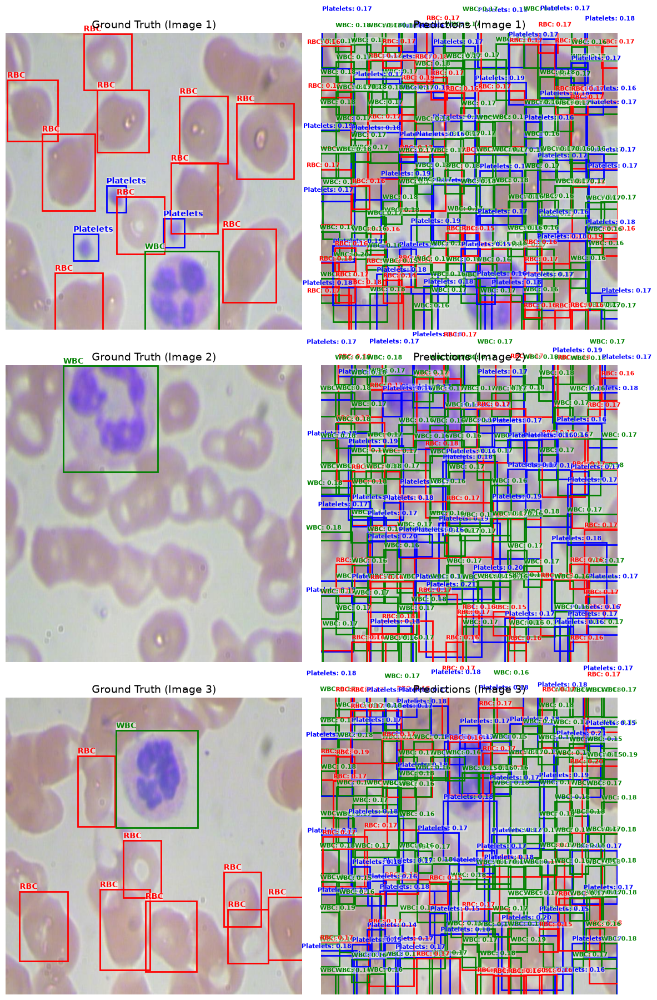

In [18]:
# CELL 5.6: Pre-Training Visualization (Zero-Shot)
print("\n--- Visualizing Predictions BEFORE Training ---")
print("Notice how the boxes are random noise because the DetectionHead is randomlisinstancey initialized.")

# Using a low threshold (0.1) just so we can see the random garbage it tries to predict
plot_comparisons(model, val_loader, device, anchors, num_images=3, conf_thresh=0.1)

### Transfer learning

In [19]:
# Re-seed right before training so the training run itself is
# reproducible regardless of how much randomness earlier cells
# (anchor search, pre-training viz, etc.) already consumed.
set_seed(SEED)

# Freeze Stage A and Stage B
for param in model.stage_a.parameters():
    param.requires_grad = False
for param in model.stage_b.parameters():
    param.requires_grad = False

# We only train the detection head
optimizer = optim.Adam(model.head.parameters(), lr=1e-4, weight_decay=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=4,
    threshold=0.01,
    threshold_mode='rel'
)

EPOCHS = 30
train_losses = []
val_losses = []

print("\n--- Starting Transfer Learning ---")
for epoch in range(EPOCHS):
    model.train()
    model.stage_a.eval()
    model.stage_b.eval()
    epoch_loss = 0
    
    for batch_idx, (images, targets) in enumerate(train_loader):
        images, targets = images.to(device), targets.to(device)
        
        optimizer.zero_grad()
        predictions = model(images)
        
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    # =========================
    # Validation
    # =========================
    model.eval()

    epoch_val_loss = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            predictions = model(images)
            loss = criterion(predictions, targets)

            epoch_val_loss += loss.item()

    avg_val_loss = epoch_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    scheduler.step(avg_val_loss)
    
    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )


--- Starting Transfer Learning ---


/tmp/ipykernel_8850/3503680706.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_8850/3503680706.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


Epoch [1/30] | Train Loss: 336.3167 | Val Loss: 134.5811
Epoch [2/30] | Train Loss: 157.8908 | Val Loss: 87.7676
Epoch [3/30] | Train Loss: 78.4404 | Val Loss: 68.2628
Epoch [4/30] | Train Loss: 93.4300 | Val Loss: 50.8365
Epoch [5/30] | Train Loss: 53.6599 | Val Loss: 43.5465
Epoch [6/30] | Train Loss: 37.7534 | Val Loss: 39.3409
Epoch [7/30] | Train Loss: 37.2914 | Val Loss: 39.1989
Epoch [8/30] | Train Loss: 37.8277 | Val Loss: 37.3580
Epoch [9/30] | Train Loss: 32.8768 | Val Loss: 37.0838
Epoch [10/30] | Train Loss: 31.3274 | Val Loss: 37.6696
Epoch [11/30] | Train Loss: 36.8062 | Val Loss: 35.5806
Epoch [12/30] | Train Loss: 27.0970 | Val Loss: 36.8160
Epoch [13/30] | Train Loss: 24.2123 | Val Loss: 38.2211
Epoch [14/30] | Train Loss: 20.9065 | Val Loss: 36.7699
Epoch [15/30] | Train Loss: 18.5934 | Val Loss: 39.6826
Epoch [16/30] | Train Loss: 17.4585 | Val Loss: 39.2627
Epoch [17/30] | Train Loss: 13.2425 | Val Loss: 39.5078
Epoch [18/30] | Train Loss: 9.7905 | Val Loss: 39.6732


--- Post-Training Evaluation ---


/tmp/ipykernel_8850/3503680706.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_8850/3503680706.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


Validation Loss: 46.1349


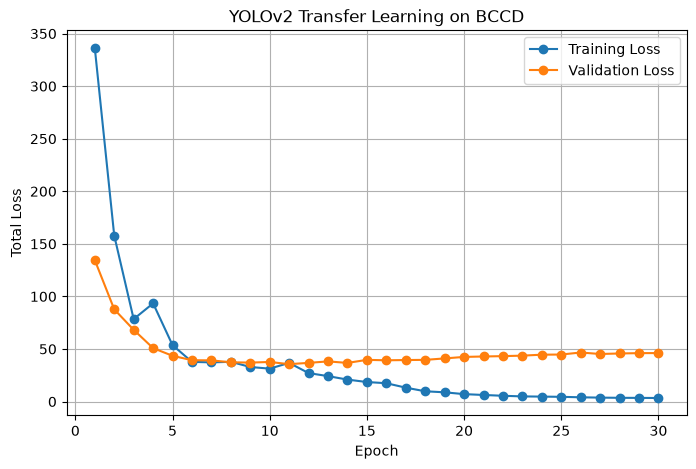

In [20]:
from matplotlib import pyplot as plt

print("\n--- Post-Training Evaluation ---")
evaluate_model(model, val_loader, criterion, device)

# Plot training and validation loss curves
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker='o',
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    marker='o',
    label="Validation Loss"
)

plt.title("YOLOv2 Transfer Learning on BCCD")
plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.legend()
plt.grid(True)
plt.show()

### Visualising some images from validation set on transfer learnt model


--- Visualizing Predictions AFTER Transfer Learning ---
Left: Labeled Ground Truth | Right: Model Predictions


/tmp/ipykernel_8850/3503680706.py:67: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(w / self.anchors[best_anchor][0] + 1e-16)), # w transform
/tmp/ipykernel_8850/3503680706.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(h / self.anchors[best_anchor][1] + 1e-16))  # h transform


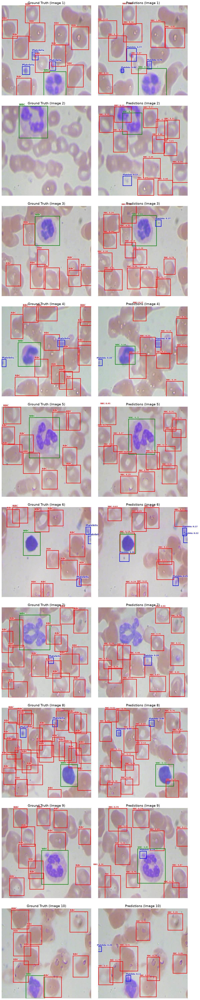

In [21]:
print("\n--- Visualizing Predictions AFTER Transfer Learning ---")
print("Left: Labeled Ground Truth | Right: Model Predictions")

plot_comparisons(model, val_loader, device, anchors, num_images=10, conf_thresh=0.1,iou_thresh=0.15)